# Plant Leaf Disease Classification with Handcrafted Features

This notebook rebuilds the PlantVillage workflow around duplicate-aware evaluation. Duplicate groups are found before splitting, feature extraction is fit-free, the test partition is held back from selection, and all reported metrics are generated by the cells below.

## Roadmap

Dataset exploration → exact and perceptual duplicate audit → group-aware 64/16/20 split → baseline and validation experiments → final evaluation → inference and artifacts.


## 1. Project Overview

## 2. Imports and Reproducibility

In [32]:
import json
# Operating system and file path utilities
import os
import hashlib
import sys
import time
import zipfile
import random
from pathlib import Path
from collections import Counter

# Core scientific computation and data manipulation
import numpy as np
import pandas as pd

# Image processing and manipulation
import cv2
from PIL import Image

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Handcrafted feature extraction from scikit-image
from skimage.feature import (
    local_binary_pattern,
    graycomatrix,
    graycoprops,
    hog
)

# Machine learning pipelines, algorithms, and evaluation metrics from scikit-learn
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    log_loss
)
import joblib

# Display utility fallback
try:
    from IPython.display import display
except ImportError:
    display = print

# Configure plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
sns.set_palette("Set2")

# Set global random seeds for full reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ All required libraries imported successfully!")
print(f"   • Python:       {sys.version.split()[0]}")
print(f"   • NumPy:        {np.__version__}")
print(f"   • Pandas:       {pd.__version__}")
print(f"   • OpenCV:       {cv2.__version__}")
print(f"   • Scikit-Learn: {sklearn.__version__}")



✅ All required libraries imported successfully!
   • Python:       3.14.9
   • NumPy:        2.5.4
   • Pandas:       3.1.1
   • OpenCV:       5.0.0
   • Scikit-Learn: 1.9.1


## 3. Dataset Loading and Exploration

In [33]:
# -----------------------------------------------------------------------------
# 1. Environment Detection & Path Resolution
# -----------------------------------------------------------------------------
IN_COLAB = "google.colab" in sys.modules

# Set this explicitly when your dataset is stored in a custom location.
# In Colab, upload plant-dataset.zip to /content or set this to your extracted folder.
# Examples: Path("/content/plant_disease_data/PlantVillage") or
# Path("/content/drive/MyDrive/PlantVillage")
DATASET_DIR_OVERRIDE = None

# Common locations in this repository, Colab, and Google Drive.
POSSIBLE_DATA_DIRS = [
    Path("data/raw/plantvillage/PlantVillage"),
    Path("data/raw/PlantVillage"),
    Path("data/raw/plantvillage"),
    Path("/content/plant_disease_data/PlantVillage"),
    Path("/content/plant_disease_data"),
    Path("/content/drive/MyDrive/PlantVillage"),
    Path("/content/drive/MyDrive/plant-disease-ml/data/raw/plantvillage/PlantVillage"),
    Path("/content/PlantVillage"),
    Path("/content/drive/MyDrive/PlantVillage"),
    Path("/content/drive/MyDrive/plant-disease-ml/data/raw/plantvillage/PlantVillage"),
    Path("./PlantVillage"),
]
if DATASET_DIR_OVERRIDE is not None:
    POSSIBLE_DATA_DIRS.insert(0, Path(DATASET_DIR_OVERRIDE))

POSSIBLE_ZIP_PATHS = [
    Path("plant-dataset.zip"),
    Path("archive.zip"),
    Path("/content/plant-dataset.zip"),
    Path("/content/archive.zip"),
    Path("/content/drive/MyDrive/plant-dataset.zip"),
    Path("/content/drive/MyDrive/archive.zip"),
    Path("data/plant-dataset.zip"),
]

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
def contains_class_images(directory):
    """Return True when this folder contains images in class subfolders."""
    return directory.is_dir() and any(
        item.is_file() and item.suffix.lower() in IMAGE_SUFFIXES
        for item in directory.rglob("*")
    )

DATASET_DIR = None
for directory in POSSIBLE_DATA_DIRS:
    if contains_class_images(directory):
        DATASET_DIR = directory
        print(f"📁 Found dataset images under: {DATASET_DIR}")
        break

# If no extracted dataset was found, extract a known ZIP archive.
if DATASET_DIR is None:
    for zip_candidate in POSSIBLE_ZIP_PATHS:
        if zip_candidate.is_file():
            print(f"📦 Found ZIP archive at: {zip_candidate}. Extracting...")
            extract_target = Path("/content/plant_disease_data" if IN_COLAB else "data/raw/PlantVillage")
            extract_target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zip_candidate, "r") as archive:
                archive.extractall(extract_target)
            # ZIP files may contain one or more enclosing folders; locate the image root.
            matches = [p for p in [extract_target, *extract_target.iterdir()] if contains_class_images(p)]
            if matches:
                DATASET_DIR = matches[0]
                print(f"✅ Extracted dataset images to: {DATASET_DIR}")
                break

if DATASET_DIR is None:
    searched = "\n".join(f"  - {path}" for path in POSSIBLE_DATA_DIRS + POSSIBLE_ZIP_PATHS)
    raise FileNotFoundError(
        "PlantVillage images were not found. In Colab, mount Google Drive or upload/extract "
        "the dataset, then set DATASET_DIR_OVERRIDE to its folder. Searched locations:\n" + searched
    )

print(f"\n✅ Using dataset folder: {DATASET_DIR.resolve()}")

# -----------------------------------------------------------------------------
# 2. Output Directories
# -----------------------------------------------------------------------------
PROJECT_ROOT = Path(".") if not IN_COLAB else Path("/content")
FEATURE_DIR = PROJECT_ROOT / "plant_features"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

for folder in [FEATURE_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Cache file paths for extracted features
X_TRAIN_FILE = FEATURE_DIR / "X_train_features.npy"
X_TEST_FILE = FEATURE_DIR / "X_test_features.npy"

# -----------------------------------------------------------------------------
# 3. Hyperparameters & Pipeline Specifications
# -----------------------------------------------------------------------------
IMAGE_SIZE = (64, 64)
RANDOM_STATE = 42
TEST_SIZE = 0.20
BATCH_SIZE = 64

# Feature extraction parameters
COLOR_HIST_BINS = 8
LBP_RADIUS = 3
LBP_POINTS = 24
GLCM_DISTANCES = [1, 3]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_LEVELS = 32
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)

# Expected feature vector dimension:
# RGB (24) + HSV (24) + LBP (26) + GLCM (48) + HOG (1,764) = 1,886
FEATURE_DIM = 1886

print("\n⚙️ Project Configuration Summary:")
print(f"   • Running in Colab:   {IN_COLAB}")
print(f"   • Dataset Directory:  {DATASET_DIR}")
print(f"   • Target Image Size:  {IMAGE_SIZE}")
print(f"   • Train / Test Split: {int((1 - TEST_SIZE)*100)}% / {int(TEST_SIZE*100)}%")
print(f"   • Feature Dimensions: {FEATURE_DIM:,} features")
print(f"   • Batch Size:         {BATCH_SIZE}")


📁 Found dataset images under: data/raw/plantvillage/PlantVillage

✅ Using dataset folder: /home/rosa/ai-exercise/plant-disease-ml/data/raw/plantvillage/PlantVillage

⚙️ Project Configuration Summary:
   • Running in Colab:   False
   • Dataset Directory:  data/raw/plantvillage/PlantVillage
   • Target Image Size:  (64, 64)
   • Train / Test Split: 80% / 20%
   • Feature Dimensions: 1,886 features
   • Batch Size:         64


In [34]:
# Supported image file extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Scan all subdirectories recursively
records = []
for file_path in sorted(DATASET_DIR.rglob("*")):
    if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
        class_name = file_path.parent.name
        # Skip top-level parent directory if misidentified as a class
        if class_name in ["PlantVillage", "raw", "data", "plant_disease_data", "PlantVillage-Dataset-master"]:
            continue
        records.append({
            "path": str(file_path),
            "class": class_name,
            "filename": file_path.name
        })

if not records:
    raise ValueError(
        f"No supported images were found under {DATASET_DIR}. "
        "Set DATASET_DIR_OVERRIDE to the folder containing the class subfolders."
    )

df_images = pd.DataFrame(records)

# Automatically filter out classes with fewer than 2 images to satisfy stratified splitting
class_counts = df_images["class"].value_counts()
classes_with_too_few_images = class_counts[class_counts < 2]

if not classes_with_too_few_images.empty:
    print(f"⚠️ Excluding {len(classes_with_too_few_images)} class(es) with only 1 image to allow stratified split:")
    for cls_name in classes_with_too_few_images.index:
        print(f"   - {cls_name}")
    # Filter the dataframe to keep classes with 2 or more images
    df_images = df_images[~df_images["class"].isin(classes_with_too_few_images.index)].copy()

# Extract plant species as an auxiliary attribute (e.g. 'Tomato', 'Pepper', 'Potato')
df_images["species"] = df_images["class"].apply(
    lambda x: x.split("___")[0].split("_")[0] if "___" in x or "_" in x else "Unknown"
)

print(f"\n✅ Dataset scanned and filtered successfully!")
print(f"   • Total Images:  {len(df_images):,}")
print(f"   • Total Classes: {df_images['class'].nunique()}")
print(f"   • Plant Species: {df_images['species'].unique().tolist()}")

# Preview top records
display(df_images.head())



✅ Dataset scanned and filtered successfully!
   • Total Images:  20,638
   • Total Classes: 15
   • Plant Species: ['Pepper', 'Potato', 'Tomato']


,path,class,filename,species
0,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Sp...,Pepper
1,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,006adb74-934f-448f-a14f-62181742127b___JR_B.Sp...,Pepper
2,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Sp...,Pepper
3,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,01613cd0-d3cd-4e96-945c-a312002037bf___JR_B.Sp...,Pepper
4,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,0169b9ac-07b9-4be1-8b85-da94481f05a4___NREC_B....,Pepper


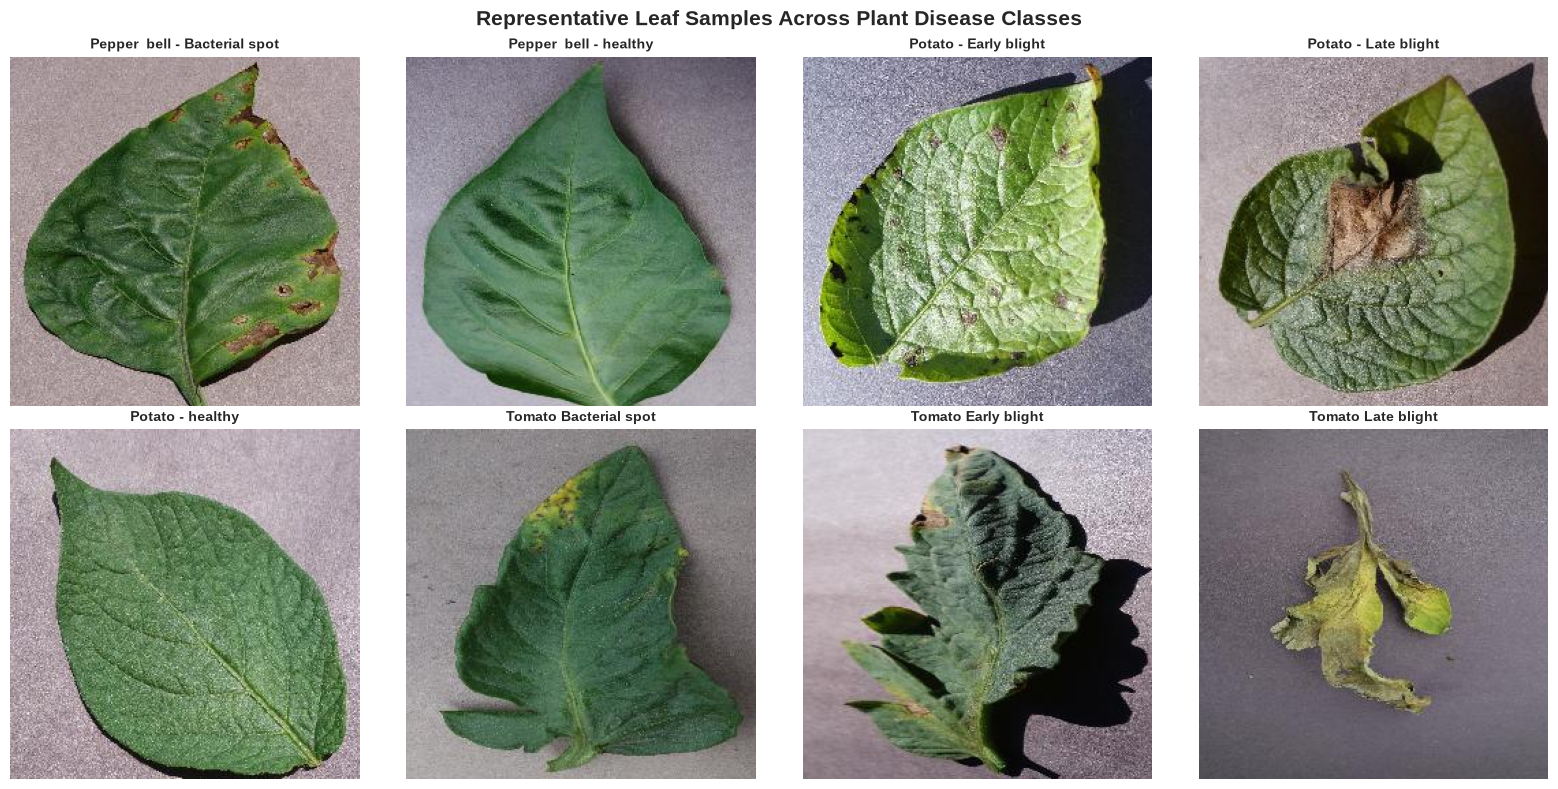

In [35]:
# -----------------------------------------------------------------------------
# 2. Visual Inspection: Sample Leaf Images
# -----------------------------------------------------------------------------
NUM_CLASSES_DISPLAY = min(8, df_images["class"].nunique())
sample_classes = df_images["class"].unique()[:NUM_CLASSES_DISPLAY]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, class_name in enumerate(sample_classes):
    sample_row = df_images[df_images["class"] == class_name].sample(1, random_state=SEED).iloc[0]
    sample_img = Image.open(sample_row["path"]).convert("RGB")

    axes[idx].imshow(sample_img)
    clean_title = class_name.replace("___", " - ").replace("_", " ")
    axes[idx].set_title(clean_title, fontsize=10, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Representative Leaf Samples Across Plant Disease Classes", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


🔍 Integrity Audit (Sample of 1000 images):
   • Corrupted Images:      0
   • Unique Dimensions:     [{'width': 256, 'height': 256}]
   • Formats Detected:      {'JPEG': 1000}
   • Color Modes Detected:  {'RGB': 1000}


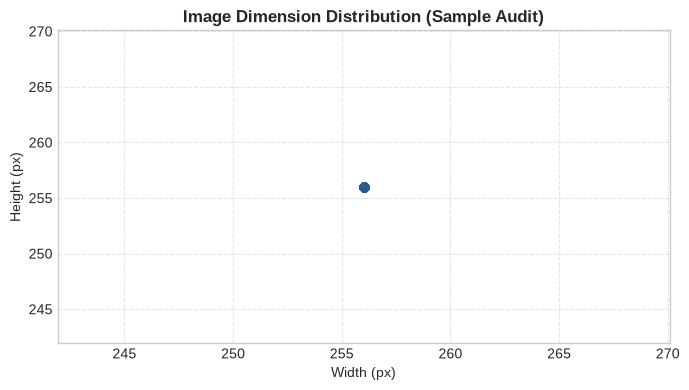

In [36]:
# -----------------------------------------------------------------------------
# 3. Image Dimension & Integrity Audit
# -----------------------------------------------------------------------------
# Audit a stratified sample of up to 1,000 images for fast, representative verification
sample_audit_paths = df_images["path"].sample(min(1000, len(df_images)), random_state=SEED)

audit_info = []
corrupted = []

for img_p in sample_audit_paths:
    try:
        with Image.open(img_p) as img:
            audit_info.append({
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "mode": img.mode
            })
    except Exception:
        corrupted.append(img_p)

df_audit = pd.DataFrame(audit_info)

print(f"🔍 Integrity Audit (Sample of {len(sample_audit_paths)} images):")
print(f"   • Corrupted Images:      {len(corrupted)}")
print(f"   • Unique Dimensions:     {df_audit[['width', 'height']].drop_duplicates().to_dict('records')}")
print(f"   • Formats Detected:      {df_audit['format'].value_counts().to_dict()}")
print(f"   • Color Modes Detected:  {df_audit['mode'].value_counts().to_dict()}")

# Scatter plot of dimensions
plt.figure(figsize=(7, 4))
plt.scatter(df_audit["width"], df_audit["height"], alpha=0.4, color="#2b5c8f")
plt.title("Image Dimension Distribution (Sample Audit)", fontsize=12, fontweight="bold")
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


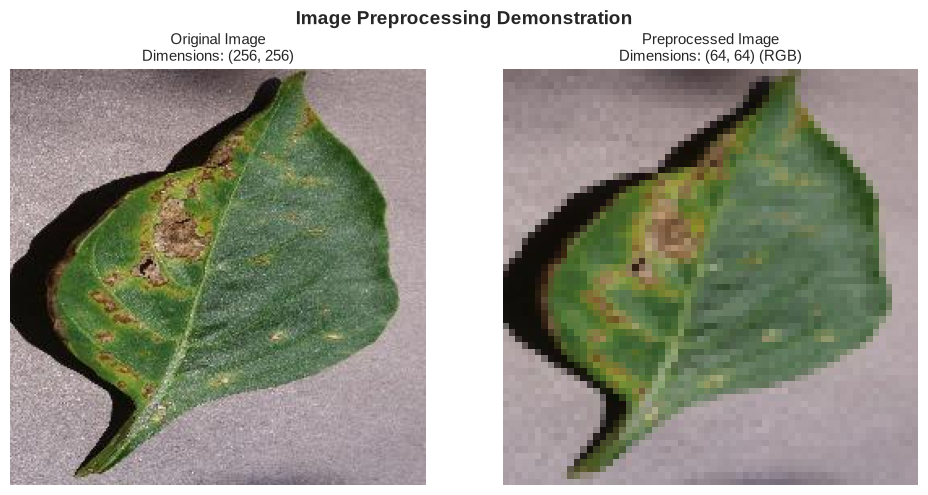

Pixel Value Range: [3, 193] | Data Type: uint8


In [37]:
def preprocess_image(image_path, image_size=IMAGE_SIZE):
    """
    Load an image from disk, convert BGR to RGB, and resize to fixed dimensions.
    """
    image = cv2.imread(str(image_path))
    if image is None:
        return None

    # Convert OpenCV BGR format to standard RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize with INTER_AREA interpolation for high-fidelity downsampling
    image = cv2.resize(image, image_size, interpolation=cv2.INTER_AREA)
    return image

# Demonstrate preprocessing on a sample leaf
sample_path = df_images.iloc[0]["path"]
sample_original = Image.open(sample_path).convert("RGB")
sample_processed = preprocess_image(sample_path, IMAGE_SIZE)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample_original)
axes[0].set_title(f"Original Image\nDimensions: {sample_original.size}", fontsize=11)
axes[0].axis("off")

axes[1].imshow(sample_processed)
axes[1].set_title(f"Preprocessed Image\nDimensions: {sample_processed.shape[:2]} (RGB)", fontsize=11)
axes[1].axis("off")

plt.suptitle("Image Preprocessing Demonstration", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Pixel Value Range: [{sample_processed.min()}, {sample_processed.max()}] | Data Type: {sample_processed.dtype}")


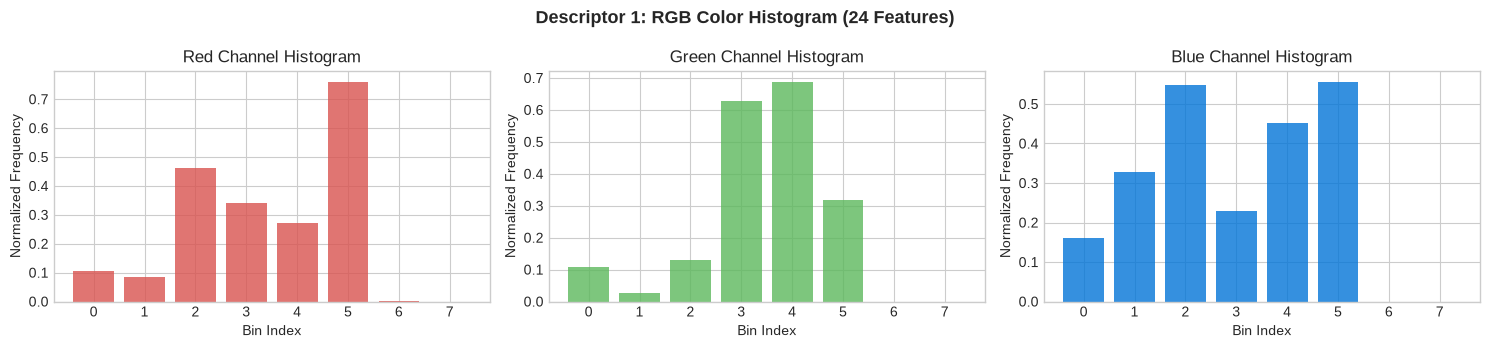

RGB feature vector shape: (24,)


In [38]:
# -----------------------------------------------------------------------------
# Descriptor 1: RGB Color Histogram (24 Features)
# -----------------------------------------------------------------------------
def extract_rgb_histogram(image, bins=COLOR_HIST_BINS):
    """Extract an 8-bin normalized histogram per RGB channel (24 features)."""
    features = []
    for channel in range(3):
        hist = cv2.calcHist([image], [channel], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        features.extend(hist)
    return np.array(features, dtype=np.float32)

rgb_feats = extract_rgb_histogram(sample_processed)

# Visualize RGB Histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
colors = ["#d9534f", "#5cb85c", "#0275d8"]
channel_names = ["Red", "Green", "Blue"]

for i, (ax, col, name) in enumerate(zip(axes, colors, channel_names)):
    ax.bar(range(COLOR_HIST_BINS), rgb_feats[i*8:(i+1)*8], color=col, alpha=0.8)
    ax.set_title(f"{name} Channel Histogram")
    ax.set_xlabel("Bin Index")
    ax.set_ylabel("Normalized Frequency")

plt.suptitle("Descriptor 1: RGB Color Histogram (24 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"RGB feature vector shape: {rgb_feats.shape}")


### Interpreting the RGB histogram

Each bar is the normalized frequency of pixels in one intensity bin for a single color channel. Peaks show which channel intensities dominate this example leaf; the three channels together summarize overall color balance. A histogram discards pixel location, so two leaves with very different lesion patterns can still have similar RGB histograms. Illumination, camera white balance, and the background can also shift these distributions. Treat this as a global color summary, not a disease diagnosis or a measure of feature importance.


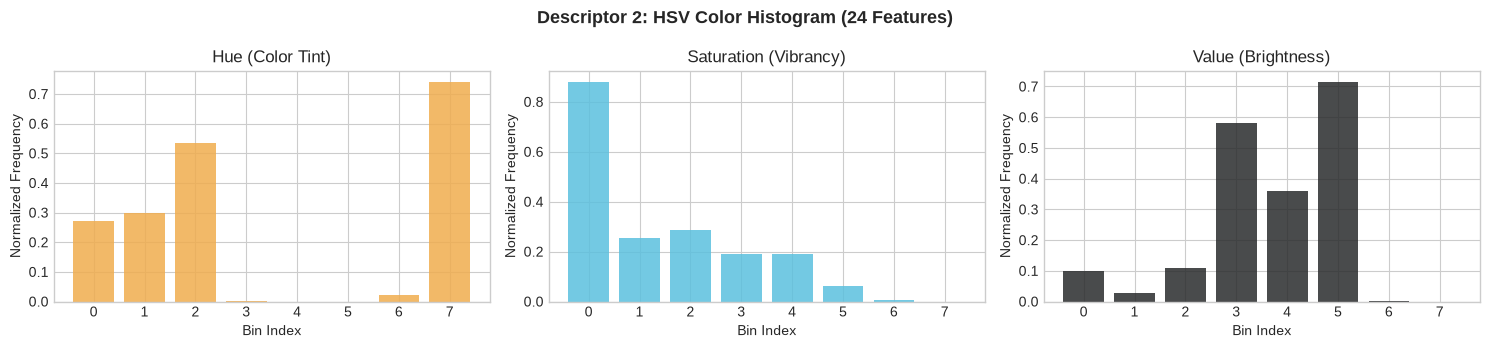

HSV feature vector shape: (24,)


In [39]:
# -----------------------------------------------------------------------------
# Descriptor 2: HSV Color Histogram (24 Features)
# -----------------------------------------------------------------------------
def extract_hsv_histogram(image, bins=COLOR_HIST_BINS):
    """Extract an 8-bin normalized histogram per HSV channel (24 features)."""
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    features = []
    # OpenCV HSV ranges: H in [0, 180], S in [0, 256], V in [0, 256]
    ranges = [[0, 180], [0, 256], [0, 256]]

    for ch, val_range in enumerate(ranges):
        hist = cv2.calcHist([hsv_image], [ch], None, [bins], val_range)
        hist = cv2.normalize(hist, hist).flatten()
        features.extend(hist)
    return np.array(features, dtype=np.float32)

hsv_feats = extract_hsv_histogram(sample_processed)

# Visualize HSV Histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
hsv_names = ["Hue (Color Tint)", "Saturation (Vibrancy)", "Value (Brightness)"]
palette_hsv = ["#f0ad4e", "#5bc0de", "#292b2c"]

for i, (ax, col, name) in enumerate(zip(axes, palette_hsv, hsv_names)):
    ax.bar(range(COLOR_HIST_BINS), hsv_feats[i*8:(i+1)*8], color=col, alpha=0.85)
    ax.set_title(f"{name}")
    ax.set_xlabel("Bin Index")
    ax.set_ylabel("Normalized Frequency")

plt.suptitle("Descriptor 2: HSV Color Histogram (24 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"HSV feature vector shape: {hsv_feats.shape}")


### Interpreting the HSV histogram

Hue summarizes color family, saturation summarizes color vividness, and value summarizes brightness. HSV can make color shifts easier to describe than raw RGB, but it is not independent evidence: it is a deterministic transform of the same pixels. Hue is unstable for nearly gray or low-saturation pixels, while value remains sensitive to lighting. The validation ablation later checks whether HSV adds useful information beyond RGB; the plot alone cannot establish that.


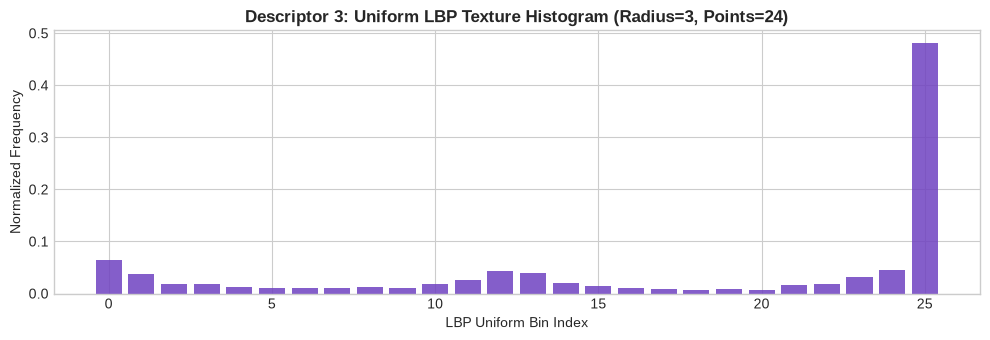

LBP feature vector shape: (26,)


In [40]:
# -----------------------------------------------------------------------------
# Descriptor 3: Uniform Local Binary Patterns (LBP) (26 Features)
# -----------------------------------------------------------------------------
def extract_lbp_features(image, radius=LBP_RADIUS, points=LBP_POINTS):
    """Extract uniform Local Binary Patterns texture histogram (P + 2 = 26 bins)."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, points, radius, method="uniform")
    num_bins = points + 2
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, num_bins + 1), range=(0, num_bins))
    hist = hist.astype(np.float32)
    hist /= (hist.sum() + 1e-7)
    return hist

lbp_feats = extract_lbp_features(sample_processed)

# Visualize LBP Histogram
plt.figure(figsize=(10, 3.5))
plt.bar(range(len(lbp_feats)), lbp_feats, color="#6f42c1", alpha=0.85)
plt.title(f"Descriptor 3: Uniform LBP Texture Histogram (Radius={LBP_RADIUS}, Points={LBP_POINTS})", fontsize=12, fontweight="bold")
plt.xlabel("LBP Uniform Bin Index")
plt.ylabel("Normalized Frequency")
plt.tight_layout()
plt.show()
print(f"LBP feature vector shape: {lbp_feats.shape}")


### Interpreting the LBP histogram

LBP counts local grayscale texture patterns. A high bar means that pattern occurs often in the sample, which can reflect smooth areas, edges, or small spots depending on the pattern. The histogram preserves local texture frequencies but discards where each pattern occurs. Radius and point count set the texture scale, and resizing to 64 × 64 can remove small lesions. Compare class usefulness with validation metrics rather than inferring disease from one sample histogram.


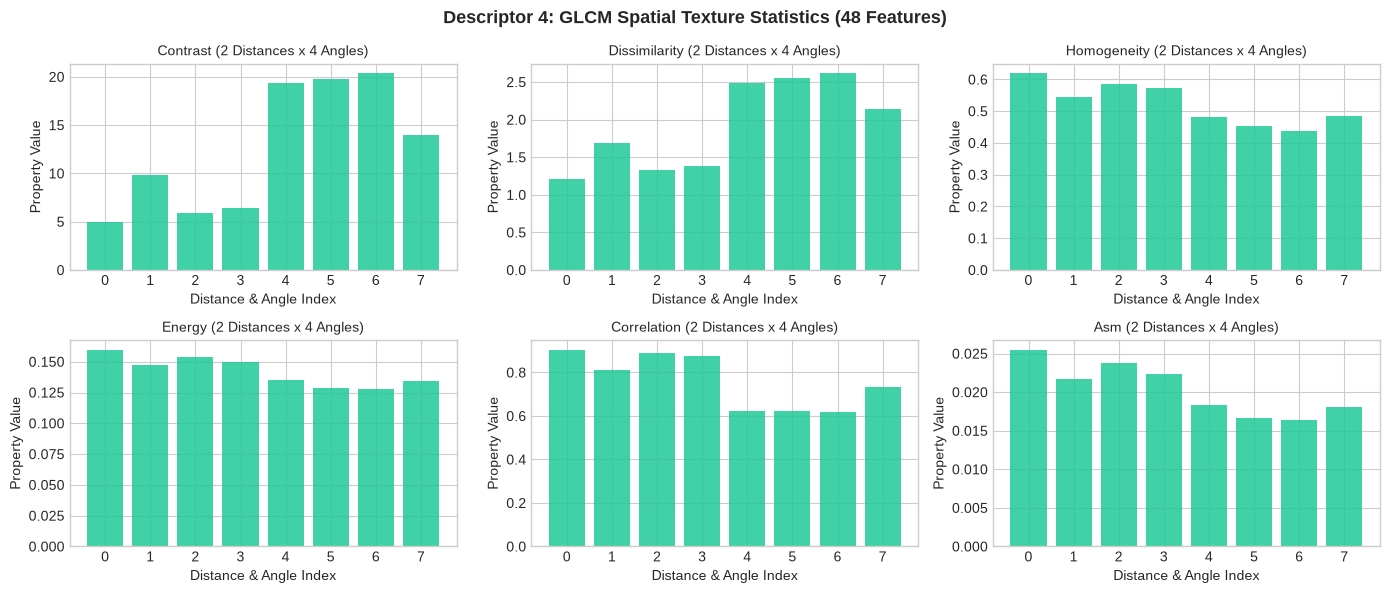

GLCM feature vector shape: (48,)


In [41]:
# -----------------------------------------------------------------------------
# Descriptor 4: Gray-Level Co-occurrence Matrix (GLCM) (48 Features)
# -----------------------------------------------------------------------------
def extract_glcm_features(image):
    """
    Extract statistical GLCM texture properties:
    6 properties x 2 distances x 4 angles = 48 numerical features.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # Quantize grayscale image to 32 levels to capture stable spatial co-occurrence
    gray_quantized = (gray // 8).astype(np.uint8)

    glcm = graycomatrix(
        gray_quantized,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=GLCM_LEVELS,
        symmetric=True,
        normed=True
    )

    properties = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    features = []
    for prop in properties:
        values = graycoprops(glcm, prop)
        features.extend(values.flatten())
    return np.array(features, dtype=np.float32)

glcm_feats = extract_glcm_features(sample_processed)

# Visualize GLCM Properties across directional angles
glcm_props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
axes = axes.flatten()

for idx, prop in enumerate(glcm_props):
    sub_vals = glcm_feats[idx*8:(idx+1)*8]
    axes[idx].bar(range(len(sub_vals)), sub_vals, color="#20c997", alpha=0.85)
    axes[idx].set_title(f"{prop.capitalize()} (2 Distances x 4 Angles)", fontsize=10)
    axes[idx].set_xlabel("Distance & Angle Index")
    axes[idx].set_ylabel("Property Value")

plt.suptitle("Descriptor 4: GLCM Spatial Texture Statistics (48 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"GLCM feature vector shape: {glcm_feats.shape}")


### Interpreting the GLCM properties

Each group of eight bars reports one statistic across two pixel distances and four directions. Contrast and dissimilarity rise with stronger neighboring gray-level changes; homogeneity and energy are higher when co-occurrence is more concentrated; correlation measures neighbor dependence; ASM is the squared energy. Directional differences can reveal texture orientation. These summaries depend on grayscale quantization and resizing, and the bars use different numeric scales across properties, so compare a property across settings rather than comparing bar heights between properties.


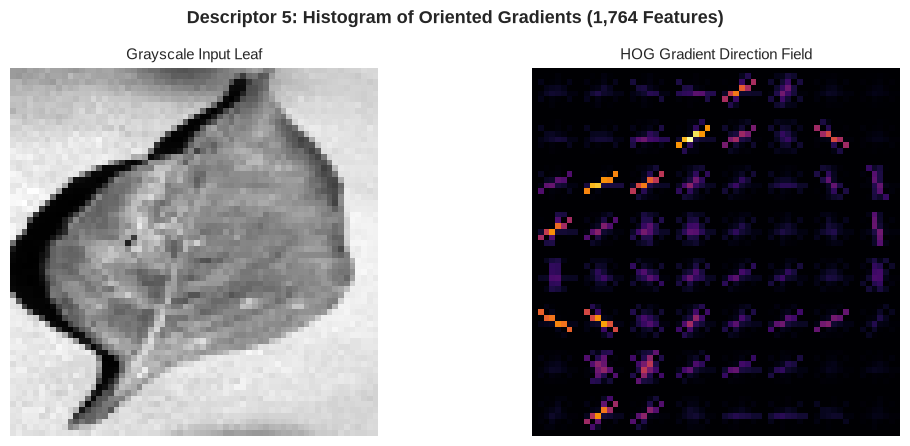

HOG feature vector shape: (1764,)


In [42]:
# -----------------------------------------------------------------------------
# Descriptor 5: Histogram of Oriented Gradients (HOG) (1,764 Features)
# -----------------------------------------------------------------------------
def extract_hog_features(image):
    """Extract HOG gradient direction and edge magnitude features (1,764 features)."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    features = hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        feature_vector=True
    )
    return features.astype(np.float32)

hog_feats = extract_hog_features(sample_processed)

# Visualize HOG gradient field alongside original grayscale
gray_sample = cv2.cvtColor(sample_processed, cv2.COLOR_RGB2GRAY)
_, hog_vis = hog(
    gray_sample,
    orientations=HOG_ORIENTATIONS,
    pixels_per_cell=HOG_PIXELS_PER_CELL,
    cells_per_block=HOG_CELLS_PER_BLOCK,
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(gray_sample, cmap="gray")
axes[0].set_title("Grayscale Input Leaf", fontsize=11)
axes[0].axis("off")

axes[1].imshow(hog_vis, cmap="inferno")
axes[1].set_title("HOG Gradient Direction Field", fontsize=11)
axes[1].axis("off")

plt.suptitle("Descriptor 5: Histogram of Oriented Gradients (1,764 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"HOG feature vector shape: {hog_feats.shape}")


### Interpreting the HOG visualization

HOG summarizes local edge directions and magnitudes, emphasizing shape and boundaries rather than color. Brighter regions in the visualization indicate stronger gradient structure, which may come from leaf edges, veins, lesions, or background boundaries. HOG has 1,764 dimensions here, far more than the other descriptors combined; that means higher storage and computation, not automatically greater predictive value. Its contribution is assessed by the held-out validation ablation.


In [43]:
# -----------------------------------------------------------------------------
# Unified Composite Feature Extractor (1,886 Features)
# -----------------------------------------------------------------------------
def extract_all_features(image_path, image_size=IMAGE_SIZE):
    """
    Extract and fuse all 5 handcrafted feature groups from a leaf image file.
    Returns a 1D float32 array of shape (1886,).
    """
    image = preprocess_image(image_path, image_size=image_size)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    rgb_f = extract_rgb_histogram(image)
    hsv_f = extract_hsv_histogram(image)
    lbp_f = extract_lbp_features(image)
    glcm_f = extract_glcm_features(image)
    hog_f = extract_hog_features(image)

    combined = np.concatenate([rgb_f, hsv_f, lbp_f, glcm_f, hog_f])
    return combined.astype(np.float32)

# Verify composite feature extraction on sample image
sample_features = extract_all_features(sample_path)

feature_breakdown = pd.DataFrame([
    {"Descriptor": "RGB Color Histogram", "Dimension": len(rgb_feats), "Proportion": f"{len(rgb_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "HSV Color Histogram", "Dimension": len(hsv_feats), "Proportion": f"{len(hsv_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "Uniform LBP Texture", "Dimension": len(lbp_feats), "Proportion": f"{len(lbp_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "GLCM Spatial Statistics", "Dimension": len(glcm_feats), "Proportion": f"{len(glcm_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "HOG Edge & Shape", "Dimension": len(hog_feats), "Proportion": f"{len(hog_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "TOTAL COMBINED", "Dimension": len(sample_features), "Proportion": "100.0%"}
])

print("✅ Combined Feature Vector Validated:")
print(f"   • Vector Length:     {len(sample_features):,}")
print(f"   • Data Type:         {sample_features.dtype}")
print(f"   • All Finite (NaN/Inf free): {np.isfinite(sample_features).all()}")

display(feature_breakdown)


✅ Combined Feature Vector Validated:
   • Vector Length:     1,886
   • Data Type:         float32
   • All Finite (NaN/Inf free): True


,Descriptor,Dimension,Proportion
0,RGB Color Histogram,24,1.27%
1,HSV Color Histogram,24,1.27%
2,Uniform LBP Texture,26,1.38%
3,GLCM Spatial Statistics,48,2.55%
4,HOG Edge & Shape,1764,93.53%
5,TOTAL COMBINED,1886,100.0%


### Reading the feature-size summary

The dimension proportion is the share of the 1,886-element vector occupied by each descriptor. It is a bookkeeping measure only: HOG's large share does not imply that it is more informative, and the normalized histogram groups are not directly comparable by raw magnitude. `FEATURE_ORDER` fixes the concatenation order used in training and prediction. The ablation study, not this table, is the evidence for whether a group improves validation performance.


## 4. Data Quality and Duplicate Detection

SHA-256 identifies byte-identical files. A 64-bit DCT perceptual hash identifies visually similar images; candidate pairs within the documented Hamming threshold are merged transitively. Any connected group with conflicting folder labels is reported and excluded from supervised modeling rather than assigned an invented label. This is a visual similarity audit, not proof of plant/session identity.


In [44]:
from collections import defaultdict
from itertools import combinations
from scipy.fftpack import dct

PHASH_SIZE = 8
PHASH_MAX_HAMMING = 4

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def perceptual_hash_bytes(encoded_image, hash_size=PHASH_SIZE):
    """DCT perceptual hash from encoded bytes; OpenCV decodes/resizes efficiently."""
    gray=cv2.imdecode(np.frombuffer(encoded_image,dtype=np.uint8),cv2.IMREAD_GRAYSCALE)
    if gray is None: raise ValueError("Could not decode image for perceptual hash")
    gray=cv2.resize(gray,(hash_size*4,hash_size*4),interpolation=cv2.INTER_AREA)
    low=cv2.dct(gray.astype(np.float32))[:hash_size,:hash_size]
    median=np.median(low.flatten()[1:])
    bits=low.flatten()>median
    value=0
    for bit in bits: value=(value<<1)|int(bit)
    return value

class UnionFind:
    def __init__(self, n): self.parent=list(range(n)); self.rank=[0]*n
    def find(self,x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]; x=self.parent[x]
        return x
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a==b: return
        if self.rank[a]<self.rank[b]: a,b=b,a
        self.parent[b]=a
        if self.rank[a]==self.rank[b]: self.rank[a]+=1

audit_records=[{"path":str(path),"label":str(label)} for path,label in zip(df_images.path,df_images["class"])]
uf=UnionFind(len(audit_records)); sha_groups=defaultdict(list)
hashes=[]; phashes=[]
for i,r in enumerate(audit_records):
    encoded=Path(r["path"]).read_bytes()
    digest=hashlib.sha256(encoded).hexdigest()
    hashes.append(digest); sha_groups[digest].append(i)
    phashes.append(perceptual_hash_bytes(encoded))
    if (i+1)%2000==0: print(f"Hashed {i+1:,}/{len(audit_records):,} images")
for group in sha_groups.values():
    for i in group[1:]: uf.union(group[0],i)
# Collapse identical perceptual hashes before candidate search to avoid redundant image pairs.
phash_groups=defaultdict(list)
for i,h in enumerate(phashes): phash_groups[h].append(i)
unique_phashes=list(phash_groups)
for indices in phash_groups.values():
    for i in indices[1:]: uf.union(indices[0],i)

# Five-band Hamming LSH: any distinct pair within four bits shares at least one band.
widths=[13,13,13,13,12]; offsets=np.cumsum([0]+widths[:-1]).tolist()
buckets=[defaultdict(list) for _ in widths]
for representative,h in enumerate(unique_phashes):
    for band,(offset,width) in enumerate(zip(offsets,widths)):
        buckets[band][(h>>offset)&((1<<width)-1)].append(representative)
near_pairs=[]; seen_pairs=set()
for band in buckets:
    for representatives in band.values():
        if len(representatives)<2: continue
        for pos,left in enumerate(representatives):
            for right in representatives[pos+1:]:
                pair=(left,right) if left<right else (right,left)
                if pair in seen_pairs: continue
                seen_pairs.add(pair)
                h_left=unique_phashes[left]; h_right=unique_phashes[right]
                if (h_left^h_right).bit_count()<=PHASH_MAX_HAMMING:
                    uf.union(phash_groups[h_left][0],phash_groups[h_right][0])
                    near_pairs.append(pair)
groups=defaultdict(list)
for i in range(len(audit_records)): groups[uf.find(i)].append(i)
duplicate_groups=[g for g in groups.values() if len(g)>1]
conflicting_groups=[g for g in duplicate_groups if len({audit_records[i]["label"] for i in g})>1]
df_images=df_images.copy(); df_images["sha256"]=hashes; df_images["phash"]=[f"{h:016x}" for h in phashes]
df_images["group_id"]=[uf.find(i) for i in range(len(df_images))]
conflict_indices={i for g in conflicting_groups for i in g}
print(f"Images audited: {len(df_images):,}")
print(f"Exact duplicate groups: {sum(len(v)>1 for v in sha_groups.values()):,}")
print(f"Near-duplicate candidate pairs (Hamming <= {PHASH_MAX_HAMMING}): {len(near_pairs):,}")
print(f"Connected duplicate groups: {len(duplicate_groups):,}; conflicting-label groups: {len(conflicting_groups):,}")
if conflicting_groups:
    display(pd.DataFrame([{"path":audit_records[i]["path"],"label":audit_records[i]["label"],"group_id":uf.find(i)} for g in conflicting_groups for i in g]))
model_df=df_images.loc[~df_images.index.isin(conflict_indices)].reset_index(drop=True)
print(f"Rows excluded due to conflicting duplicate labels: {len(conflict_indices):,}; modeling rows: {len(model_df):,}")


Hashed 2,000/20,638 images
Hashed 4,000/20,638 images
Hashed 6,000/20,638 images
Hashed 8,000/20,638 images
Hashed 10,000/20,638 images
Hashed 12,000/20,638 images
Hashed 14,000/20,638 images
Hashed 16,000/20,638 images
Hashed 18,000/20,638 images
Hashed 20,000/20,638 images
Images audited: 20,638
Exact duplicate groups: 14
Near-duplicate candidate pairs (Hamming <= 4): 59
Connected duplicate groups: 72; conflicting-label groups: 11


,path,label,group_id
0,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,278
1,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___healthy,278
2,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___healthy,1053
3,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___healthy,1053
4,data/raw/plantvillage/PlantVillage/Tomato_Bact...,Tomato_Bacterial_spot,1053
5,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___healthy,1781
6,data/raw/plantvillage/PlantVillage/Tomato_Bact...,Tomato_Bacterial_spot,1781
7,data/raw/plantvillage/PlantVillage/Pepper__bel...,Pepper__bell___healthy,2089
8,data/raw/plantvillage/PlantVillage/Tomato_Bact...,Tomato_Bacterial_spot,2089
9,data/raw/plantvillage/PlantVillage/Tomato_Bact...,Tomato_Bacterial_spot,5368


Rows excluded due to conflicting duplicate labels: 23; modeling rows: 20,615


## 5. Group-Based Data Splitting

Groups are assigned whole to train, validation, or test. The seeded greedy allocator targets 64/16/20 overall and minimizes class and size deviations. Exact ratios may be infeasible for large duplicate groups or rare classes; realized ratios and class support are printed. No image-level augmentation or learned transform is applied before the split.


In [45]:
from sklearn.model_selection import GroupShuffleSplit

def grouped_stratified_three_way(frame, seed=SEED, targets=(.64,.16,.20), trials=120):
    labels=frame["class"].to_numpy(); gids=frame["group_id"].to_numpy()
    classes, yi=np.unique(labels, return_inverse=True); ng=len(classes)
    unique_groups=np.unique(gids); rng=np.random.default_rng(seed)
    group_rows=defaultdict(list)
    for row_index,g in enumerate(gids): group_rows[g].append(row_index)
    group_counts={g:np.bincount(yi[group_rows[g]],minlength=ng) for g in unique_groups}
    totals=np.bincount(yi,minlength=ng); best=None
    target_counts=np.asarray(targets)[:,None]*totals
    count_scale=totals[None,:]+1
    target_sizes=np.asarray(targets)*len(frame)
    size_scale=len(frame)+1
    for trial in range(trials):
        order=sorted(unique_groups,key=lambda g:(-len(group_rows[g]),rng.random()))
        bins=[[],[],[]]; counts=np.zeros((3,ng),dtype=float); sizes=np.zeros(3)
        count_cost=((counts-target_counts)/count_scale)**2
        size_cost=((sizes-target_sizes)/size_scale)**2
        class_denominator=counts.size
        for g in order:
            gc=group_counts[g]; gn=len(group_rows[g]); options=[]
            for b in range(3):
                proposed_counts=counts[b]+gc
                proposed_size=sizes[b]+gn
                proposed_class_cost=(count_cost.sum()-count_cost[b].sum()+np.sum(((proposed_counts-target_counts[b])/count_scale[0])**2))/class_denominator
                proposed_size_cost=(size_cost.sum()-size_cost[b]+((proposed_size-target_sizes[b])/size_scale)**2)/3
                options.append(proposed_class_cost+.5*proposed_size_cost)
            b=int(np.argmin(options)); bins[b].append(g); counts[b]+=gc; sizes[b]+=gn
            count_cost[b]=((counts[b]-target_counts[b])/count_scale[0])**2
            size_cost[b]=((sizes[b]-target_sizes[b])/size_scale)**2
        if min(map(len,bins))==0: continue
        score=count_cost.mean()+.5*size_cost.mean()
        if best is None or score<best[0]: best=(score,bins)
    if best is None: raise ValueError("Unable to form non-empty group partitions")
    parts=[]
    for bucket in best[1]: parts.append(np.flatnonzero(np.isin(gids,bucket)))
    return parts

train_idx,val_idx,test_idx=grouped_stratified_three_way(model_df)
train_df=model_df.iloc[train_idx].reset_index(drop=True); val_df=model_df.iloc[val_idx].reset_index(drop=True); test_df=model_df.iloc[test_idx].reset_index(drop=True)
split_lookup={}
for name,part in [("train",train_df),("validation",val_df),("test",test_df)]:
    for gid in part.group_id: split_lookup[gid]=name
X_train_paths=train_df.path.to_numpy(); y_train=train_df["class"].to_numpy()
X_val_paths=val_df.path.to_numpy(); y_val=val_df["class"].to_numpy()
X_test_paths=test_df.path.to_numpy(); y_test=test_df["class"].to_numpy()
split_report=pd.DataFrame([{"partition":name,"images":len(part),"fraction":len(part)/len(model_df),"groups":part.group_id.nunique(),"classes":part["class"].nunique()} for name,part in [("train",train_df),("validation",val_df),("test",test_df)]])
display(split_report)
print("Per-class counts by partition:"); display(pd.crosstab(model_df["class"], pd.Categorical(np.select([model_df.index.isin(train_idx),model_df.index.isin(val_idx)],['train','validation'],default='test'),categories=['train','validation','test'])))


,partition,images,fraction,groups,classes
0,train,13195,0.640068,13134,15
1,validation,3298,0.159981,3298,15
2,test,4122,0.199951,4122,15


Per-class counts by partition:


col_0,train,validation,test
class,,,
Pepper__bell___Bacterial_spot,638,159,199
Pepper__bell___healthy,943,236,294
Potato___Early_blight,640,160,200
Potato___Late_blight,640,160,200
Potato___healthy,97,24,31
Tomato_Bacterial_spot,1358,340,425
Tomato_Early_blight,640,160,200
Tomato_Late_blight,1222,305,382
Tomato_Leaf_Mold,608,152,190


## 6. Leakage Verification

In [46]:
partition_groups=[set(x.group_id) for x in (train_df,val_df,test_df)]
assert not (partition_groups[0]&partition_groups[1] or partition_groups[0]&partition_groups[2] or partition_groups[1]&partition_groups[2])
cross=[g for g in groups.values() if len({split_lookup.get(uf.find(i)) for i in g})>1]
assert not cross, f"Duplicate group crosses partitions: {len(cross)}"
print("Leakage audit passed: duplicate-connected groups are disjoint across train/validation/test.")
print(f"Duplicate groups: {len(duplicate_groups)}; conflicting-label groups excluded: {len(conflicting_groups)}")
print("Limitation: perceptual hashing cannot establish capture-session or plant identity; manually review threshold-near pairs for this dataset.")


Leakage audit passed: duplicate-connected groups are disjoint across train/validation/test.
Duplicate groups: 72; conflicting-label groups excluded: 11
Limitation: perceptual hashing cannot establish capture-session or plant identity; manually review threshold-near pairs for this dataset.


## 7. Image Preprocessing

## 8. Feature Extraction

RGB, HSV, LBP, GLCM, and HOG use the preserved extraction functions and fixed parameter order above. These are deterministic per-image transforms, so there is no dataset-fitted preprocessing. Cache keys include ordered paths and feature settings.


In [47]:
FEATURE_GROUPS={"RGB":slice(0,24),"HSV":slice(24,48),"LBP":slice(48,74),"GLCM":slice(74,122),"HOG":slice(122,FEATURE_DIM)}
FEATURE_ORDER=list(FEATURE_GROUPS)
def extract_matrix(paths, batch_size=64):
    out=np.empty((len(paths),FEATURE_DIM),dtype=np.float32)
    for start in range(0,len(paths),batch_size):
        out[start:start+batch_size]=np.vstack([extract_all_features(p) for p in paths[start:start+batch_size]])
        if (start//batch_size)%25==0: print(f"Extracted {min(start+batch_size,len(paths)):,}/{len(paths):,}")
    return out
def feature_cache(paths, name):
    target=FEATURE_DIR/f"{name}_features.npy"; manifest=target.with_suffix('.json')
    signature=hashlib.sha256(json.dumps({"paths":list(map(str,paths)),"image_size":IMAGE_SIZE,"groups":FEATURE_ORDER}).encode()).hexdigest()
    if target.exists() and manifest.exists() and json.loads(manifest.read_text()).get("signature")==signature:
        return np.load(target,mmap_mode="r")
    arr=extract_matrix(paths); np.save(target,arr); manifest.write_text(json.dumps({"signature":signature,"shape":arr.shape,"dtype":str(arr.dtype)})); return arr

X_train_features=feature_cache(X_train_paths,"group_train")
X_val_features=feature_cache(X_val_paths,"group_validation")
X_test_features=feature_cache(X_test_paths,"group_test")
print("Feature matrix shapes:",X_train_features.shape,X_val_features.shape,X_test_features.shape)


Feature matrix shapes: (13195, 1886) (3298, 1886) (4122, 1886)


## 9. Baseline Models

## 10. Baseline Evaluation

In [48]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score)
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

def macro_ovr_auc(y_true, scores, classes):
    """Compute macro one-vs-rest AUC from probabilities or decision scores."""
    classes=np.asarray(classes)
    scores=np.asarray(scores)
    if len(classes)==2:
        # Binary LinearSVC returns one signed score; positive favors classes[1].
        positive_scores=scores if scores.ndim==1 else scores[:,1]
        return roc_auc_score(np.asarray(y_true)==classes[1],positive_scores)
    if scores.ndim!=2 or scores.shape[1]!=len(classes):
        raise ValueError(f"Expected one score column per class ({len(classes)}); got {scores.shape}")
    y_true=np.asarray(y_true)
    aucs=[]
    for column,label in enumerate(classes):
        binary_target=(y_true==label).astype(np.uint8)
        # A class absent from this partition has no defined one-vs-rest AUC.
        if binary_target.min()!=binary_target.max():
            aucs.append(roc_auc_score(binary_target,scores[:,column]))
    return float(np.mean(aucs)) if aucs else float("nan")

def score_model(model,X,y):
    pred=model.predict(X); out={"Accuracy":accuracy_score(y,pred),"Macro Precision":precision_score(y,pred,average="macro",zero_division=0),"Macro Recall":recall_score(y,pred,average="macro",zero_division=0),"Macro F1":f1_score(y,pred,average="macro",zero_division=0),"Weighted F1":f1_score(y,pred,average="weighted",zero_division=0)}
    if hasattr(model,"predict_proba"):
        out["Macro ROC-AUC OVR"]=macro_ovr_auc(y,model.predict_proba(X),model.classes_)
    elif hasattr(model,"decision_function"):
        # Raw decision scores are valid ranking scores for one-vs-rest ROC-AUC;
        # they are not probabilities and are not described as confidence.
        out["Macro ROC-AUC OVR"]=macro_ovr_auc(y,model.decision_function(X),model.classes_)
    return pred,out

baseline_models={
 "Linear SVM":make_pipeline(StandardScaler(),LinearSVC(C=1.0,loss="squared_hinge",class_weight=None,dual="auto",max_iter=5000,random_state=SEED)),
 "Random Forest":RandomForestClassifier(n_estimators=200,class_weight=None,n_jobs=-1,random_state=SEED)
}
baseline_rows=[]; baseline_predictions={}
for name,model in baseline_models.items():
 t=time.perf_counter(); model.fit(X_train_features,y_train); train_s=time.perf_counter()-t
 t=time.perf_counter(); pred,metrics=score_model(model,X_val_features,y_val); pred_s=time.perf_counter()-t
 baseline_predictions[name]=pred; baseline_rows.append({"Model":name,"Training seconds":train_s,"Prediction seconds":pred_s,**metrics})
baseline_results=pd.DataFrame(baseline_rows); display(baseline_results)
for name,pred in baseline_predictions.items(): print("\n",name,"validation report\n",classification_report(y_val,pred,zero_division=0))


,Model,Training seconds,Prediction seconds,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC OVR
0,Linear SVM,2062.724467,0.153251,0.807459,0.754618,0.763917,0.757262,0.805180,0.972659
1,Random Forest,15.469160,0.258105,0.835961,0.865575,0.762004,0.781722,0.829234,0.984178



 Linear SVM validation report
                                              precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.79      0.75      0.77       159
                     Pepper__bell___healthy       0.84      0.91      0.87       236
                      Potato___Early_blight       0.82      0.88      0.85       160
                       Potato___Late_blight       0.77      0.70      0.73       160
                           Potato___healthy       0.41      0.54      0.46        24
                      Tomato_Bacterial_spot       0.86      0.91      0.88       340
                        Tomato_Early_blight       0.61      0.49      0.54       160
                         Tomato_Late_blight       0.75      0.68      0.71       305
                           Tomato_Leaf_Mold       0.73      0.78      0.76       152
                  Tomato_Septoria_leaf_spot       0.77      0.76      0.77       283
Tomato_Spider_mites_Two_spotted_

### Training and validation loss progression

This figure plots **multiclass log loss** on the fit data and validation partition as model complexity grows. The Linear SVM uses sigmoid calibration so both splits have class probabilities; its checkpoints add more training examples. The Random Forest checkpoints add trees to a warm-started forest. This is a learning/progression curve, not an epoch curve. Only training and validation data are used; the test partition remains untouched.


/home/rosa/ai-exercise/plant-disease-ml/.venv-1/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/rosa/ai-exercise/plant-disease-ml/.venv-1/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(
/home/rosa/ai-exercise/plant-disease-ml/.venv-1/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs 

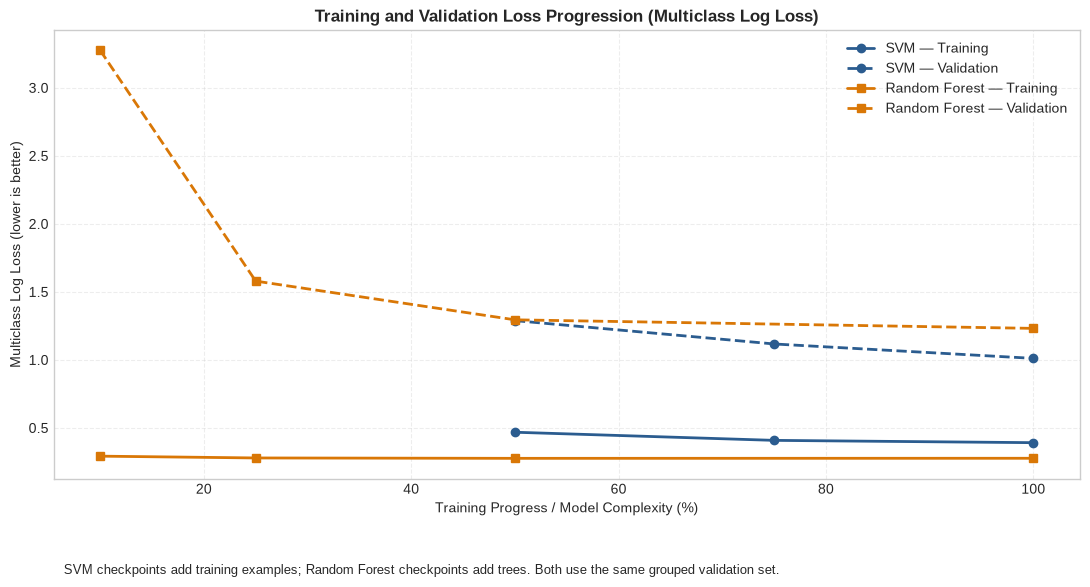

,Model,Progress (%),Split,Log loss
0,Calibrated Linear SVM,50.0,Training,0.468240
1,Calibrated Linear SVM,50.0,Validation,1.288835
2,Calibrated Linear SVM,75.0,Training,0.408475
3,Calibrated Linear SVM,75.0,Validation,1.117120
4,Calibrated Linear SVM,100.0,Training,0.391515
5,Calibrated Linear SVM,100.0,Validation,1.011239
6,Random Forest,10.0,Training,0.292408
7,Random Forest,10.0,Validation,3.275334
8,Random Forest,25.0,Training,0.279159
9,Random Forest,25.0,Validation,1.579273


In [49]:
# Training/validation loss progression; set False only when runtime is constrained.
RUN_LOSS_TRACKING=True
LOSS_TRACKING_MAX_FIT_ROWS=3000
LOSS_SAMPLE_FRACTIONS=[0.50,0.75,1.00]
LOSS_RF_TREE_COUNTS=[10,25,50,100]

if RUN_LOSS_TRACKING:
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.base import clone

    all_train_idx=np.arange(len(y_train))
    if len(all_train_idx)>LOSS_TRACKING_MAX_FIT_ROWS:
        curve_idx,_=train_test_split(all_train_idx,train_size=LOSS_TRACKING_MAX_FIT_ROWS,
            random_state=SEED,stratify=y_train)
    else:
        curve_idx=all_train_idx
    X_curve=np.asarray(X_train_features[curve_idx],dtype=np.float32)
    y_curve=np.asarray(y_train)[curve_idx]

    # Build nested, stratified checkpoints so each larger subset contains the smaller one.
    rng=np.random.default_rng(SEED)
    class_order={label:rng.permutation(np.flatnonzero(y_curve==label)) for label in np.unique(y_curve)}
    fraction_indices={}
    for fraction in LOSS_SAMPLE_FRACTIONS:
        pieces=[]
        for label,indices in class_order.items():
            take=max(3,int(round(len(indices)*fraction)))
            pieces.extend(indices[:min(take,len(indices))])
        fraction_indices[fraction]=np.asarray(pieces,dtype=int)

    loss_records=[]
    def append_log_loss(model_name,progress,estimator,x_fit,y_fit):
        for split_name,x_eval,y_eval in [("Training",x_fit,y_fit),("Validation",X_val_features,y_val)]:
            probabilities=np.clip(estimator.predict_proba(x_eval),1e-12,1.0)
            probabilities/=probabilities.sum(axis=1,keepdims=True)
            loss_records.append({"Model":model_name,"Progress (%)":progress,"Split":split_name,
                "Log loss":log_loss(y_eval,probabilities,labels=estimator.classes_)})

    for fraction,indices in fraction_indices.items():
        svm_curve=Pipeline([
            ("scaler",StandardScaler()),
            ("classifier",CalibratedClassifierCV(
                estimator=LinearSVC(class_weight="balanced",dual="auto",max_iter=5000,random_state=SEED),
                method="sigmoid",cv=3))
        ])
        svm_curve.fit(X_curve[indices],y_curve[indices])
        append_log_loss("Calibrated Linear SVM",fraction*100,svm_curve,X_curve[indices],y_curve[indices])

    rf_curve=RandomForestClassifier(n_estimators=1,warm_start=True,max_features="sqrt",
        class_weight="balanced_subsample",n_jobs=-1,random_state=SEED)
    for tree_count in LOSS_RF_TREE_COUNTS:
        rf_curve.set_params(n_estimators=tree_count)
        rf_curve.fit(X_curve,y_curve)
        append_log_loss("Random Forest",tree_count/max(LOSS_RF_TREE_COUNTS)*100,rf_curve,X_curve,y_curve)

    loss_progression=pd.DataFrame(loss_records)
    loss_progression.to_csv(RESULTS_DIR/"training_validation_loss_progression.csv",index=False)
    fig,ax=plt.subplots(figsize=(11,6))
    curves=[
        ("Calibrated Linear SVM","Training","#2b5c8f","o","-"),
        ("Calibrated Linear SVM","Validation","#2b5c8f","o","--"),
        ("Random Forest","Training","#d97706","s","-"),
        ("Random Forest","Validation","#d97706","s","--"),
    ]
    for model_name,split_name,color,marker,linestyle in curves:
        curve=loss_progression[(loss_progression.Model==model_name)&(loss_progression.Split==split_name)].sort_values("Progress (%)")
        short_name="SVM" if model_name.startswith("Calibrated") else model_name
        ax.plot(curve["Progress (%)"],curve["Log loss"],color=color,marker=marker,linestyle=linestyle,
            linewidth=2,label=f"{short_name} — {split_name}")
    ax.set_title("Training and Validation Loss Progression (Multiclass Log Loss)",fontweight="bold")
    ax.set_xlabel("Training Progress / Model Complexity (%)")
    ax.set_ylabel("Multiclass Log Loss (lower is better)")
    ax.grid(True,linestyle="--",alpha=.35); ax.legend()
    ax.text(.01,-.19,"SVM checkpoints add training examples; Random Forest checkpoints add trees. Both use the same grouped validation set.",
        transform=ax.transAxes,fontsize=9,va="top")
    fig.tight_layout(); plt.show()
    display(loss_progression)
else:
    print("Loss progression is skipped. Set RUN_LOSS_TRACKING=True to generate the figure.")


### Reading the loss curves

Solid lines show fit loss and dashed lines show validation loss. A falling pair of curves suggests more examples or ensemble capacity are helping. A low training loss with a substantially higher validation loss signals a generalization gap; similarly high curves can indicate underfitting or limited information in the features. SVM checkpoints increase the training-data fraction, while Random Forest checkpoints increase tree count, so the shared x-axis is a normalized progress/complexity scale. Compare train-to-validation gaps within each model; do not interpret the horizontal positions as the same quantity.


## 11. Feature Ablation Study

The following validation-only comparison runs all nine feature sets with a Linear SVM. Runtime is measured per fit and prediction. RGB and HSV are compared directly. Set `RUN_ABLATION=False` to skip on constrained environments.


In [50]:
RUN_ABLATION=False  # Set True to run the nine feature-set comparisons (compute intensive).
feature_sets={"RGB only":["RGB"],"HSV only":["HSV"],"LBP only":["LBP"],"GLCM only":["GLCM"],"HOG only":["HOG"],"RGB + HSV":["RGB","HSV"],"RGB + HSV + LBP":["RGB","HSV","LBP"],"RGB + HSV + LBP + GLCM":["RGB","HSV","LBP","GLCM"],"All five":FEATURE_ORDER}
def pick_features(X,names): return X[:,np.concatenate([np.arange(FEATURE_GROUPS[n].start,FEATURE_GROUPS[n].stop) for n in names])]
ablation_rows=[]
if RUN_ABLATION:
 for label,names in feature_sets.items():
  a,b=pick_features(X_train_features,names),pick_features(X_val_features,names)
  m=make_pipeline(StandardScaler(),LinearSVC(C=1,class_weight="balanced",dual="auto",max_iter=5000,random_state=SEED))
  t=time.perf_counter(); m.fit(a,y_train); fit_s=time.perf_counter()-t
  t=time.perf_counter(); pred=m.predict(b); pred_s=time.perf_counter()-t
  ablation_rows.append({"Feature set":label,"Dimensions":a.shape[1],"Fit seconds":fit_s,"Prediction seconds":pred_s,"Macro F1":f1_score(y_val,pred,average="macro"),"Weighted F1":f1_score(y_val,pred,average="weighted"),"Accuracy":accuracy_score(y_val,pred)})
 ablation_results=pd.DataFrame(ablation_rows).sort_values("Macro F1",ascending=False); display(ablation_results)
 print("RGB + HSV improves over RGB only by validation Macro F1:",float(ablation_results.set_index("Feature set").loc["RGB + HSV","Macro F1"]-ablation_results.set_index("Feature set").loc["RGB only","Macro F1"]))


### Interpreting the ablation comparison

Compare RGB-only with RGB + HSV on validation Macro F1 to answer whether HSV adds value beyond RGB. A positive difference is evidence of an improvement on this validation split; a near-zero or negative difference suggests little benefit under these settings. The other rows show the stand-alone and cumulative contribution of texture and gradient descriptors. Because many feature sets are compared on the same validation data, treat small differences as exploratory and confirm the selected configuration only once on the held-out test set.


## 12. Class Imbalance Experiments

In [51]:
RUN_IMBALANCE_EXPERIMENTS=False  # Set True to compare weighted/unweighted fits on validation.
imbalance_rows=[]
if RUN_IMBALANCE_EXPERIMENTS:
 for name,base in [("SVM",LinearSVC(C=1,dual="auto",max_iter=5000,random_state=SEED)),("Random Forest",RandomForestClassifier(n_estimators=200,n_jobs=-1,random_state=SEED))]:
  for weighting in [None,"balanced"]:
   model=make_pipeline(StandardScaler(),base.set_params(class_weight=weighting)) if name=="SVM" else RandomForestClassifier(n_estimators=200,class_weight=weighting,n_jobs=-1,random_state=SEED)
   model.fit(X_train_features,y_train); pred=model.predict(X_val_features)
   imbalance_rows.append({"Model":name,"Class weight":weighting,"Macro F1":f1_score(y_val,pred,average="macro"),"Macro Recall":recall_score(y_val,pred,average="macro"),"Weighted F1":f1_score(y_val,pred,average="weighted")})
 imbalance_results=pd.DataFrame(imbalance_rows); display(imbalance_results)
else: print("Class weighting comparisons are available by setting RUN_IMBALANCE_EXPERIMENTS=True.")
print("No synthetic image-level SMOTE is used. No image augmentation is applied; if added, it must be training-only and operate on training paths before feature extraction.")


Class weighting comparisons are available by setting RUN_IMBALANCE_EXPERIMENTS=True.
No synthetic image-level SMOTE is used. No image augmentation is applied; if added, it must be training-only and operate on training paths before feature extraction.


## 13. Hyperparameter Tuning

Grouped CV is performed within the training partition. Group labels remain intact between folds. This can be expensive; the compact search spaces below favor reproducibility over exhaustive search. Validation data chooses between tuned candidates; test data remains untouched.


In [52]:
RUN_TUNING=False  # Set True for grouped cross-validated searches (compute intensive).
tuned_candidates={}
if RUN_TUNING:
 train_groups=train_df.group_id.to_numpy()
 n_splits=min(3,len(np.unique(train_groups)))
 cv=StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=SEED)
 svm=make_pipeline(StandardScaler(),LinearSVC(dual="auto",max_iter=5000,random_state=SEED))
 svm_search=GridSearchCV(svm,{"linearsvc__C":[0.1,1,10],"linearsvc__loss":["hinge","squared_hinge"],"linearsvc__class_weight":[None,"balanced"]},scoring="f1_macro",cv=cv,n_jobs=-1,refit=True)
 svm_search.fit(X_train_features,y_train,groups=train_groups); tuned_candidates["Tuned Linear SVM"]=svm_search.best_estimator_
 rf=RandomForestClassifier(random_state=SEED,n_jobs=1)
 rf_search=RandomizedSearchCV(rf,{"n_estimators":[100,200],"max_depth":[None,30],"min_samples_split":[2,5],"min_samples_leaf":[1,2],"max_features":["sqrt",0.5],"class_weight":[None,"balanced"]},n_iter=6,scoring="f1_macro",cv=cv,n_jobs=2,random_state=SEED,refit=True)
 rf_search.fit(X_train_features,y_train,groups=train_groups); tuned_candidates["Tuned Random Forest"]=rf_search.best_estimator_
 print("SVM parameters:",svm_search.best_params_); print("RF parameters:",rf_search.best_params_)


## 14. Final Model Selection

In [53]:
candidates={**baseline_models,**tuned_candidates}
selection=[]
for name,model in candidates.items():
 pred,metrics=score_model(model,X_val_features,y_val); selection.append({"Model":name,**metrics})
selection_results=pd.DataFrame(selection).sort_values("Macro F1",ascending=False); display(selection_results)
best_name=str(selection_results.iloc[0]["Model"]); best_model=candidates[best_name]
print("Selected using validation Macro F1:",best_name)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC OVR
1,Random Forest,0.835961,0.865575,0.762004,0.781722,0.829234,0.984178
0,Linear SVM,0.807459,0.754618,0.763917,0.757262,0.805180,0.972659


Selected using validation Macro F1: Random Forest


## 15. Final Evaluation

Final test metrics (single held-out evaluation): {'Accuracy': 0.8345463367297429, 'Macro Precision': 0.8627415527515797, 'Macro Recall': 0.7623676492057839, 'Macro F1': 0.7826861008973649, 'Weighted F1': 0.8271293591171919, 'Macro ROC-AUC OVR': 0.9886003874001045}
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.88      0.69      0.78       199
                     Pepper__bell___healthy       0.84      0.94      0.88       294
                      Potato___Early_blight       0.83      0.92      0.87       200
                       Potato___Late_blight       0.86      0.59      0.70       200
                           Potato___healthy       1.00      0.16      0.28        31
                      Tomato_Bacterial_spot       0.80      0.85      0.83       425
                        Tomato_Early_blight       0.88      0.43      0.58       200
                         Tomato_Late_blight       0.83

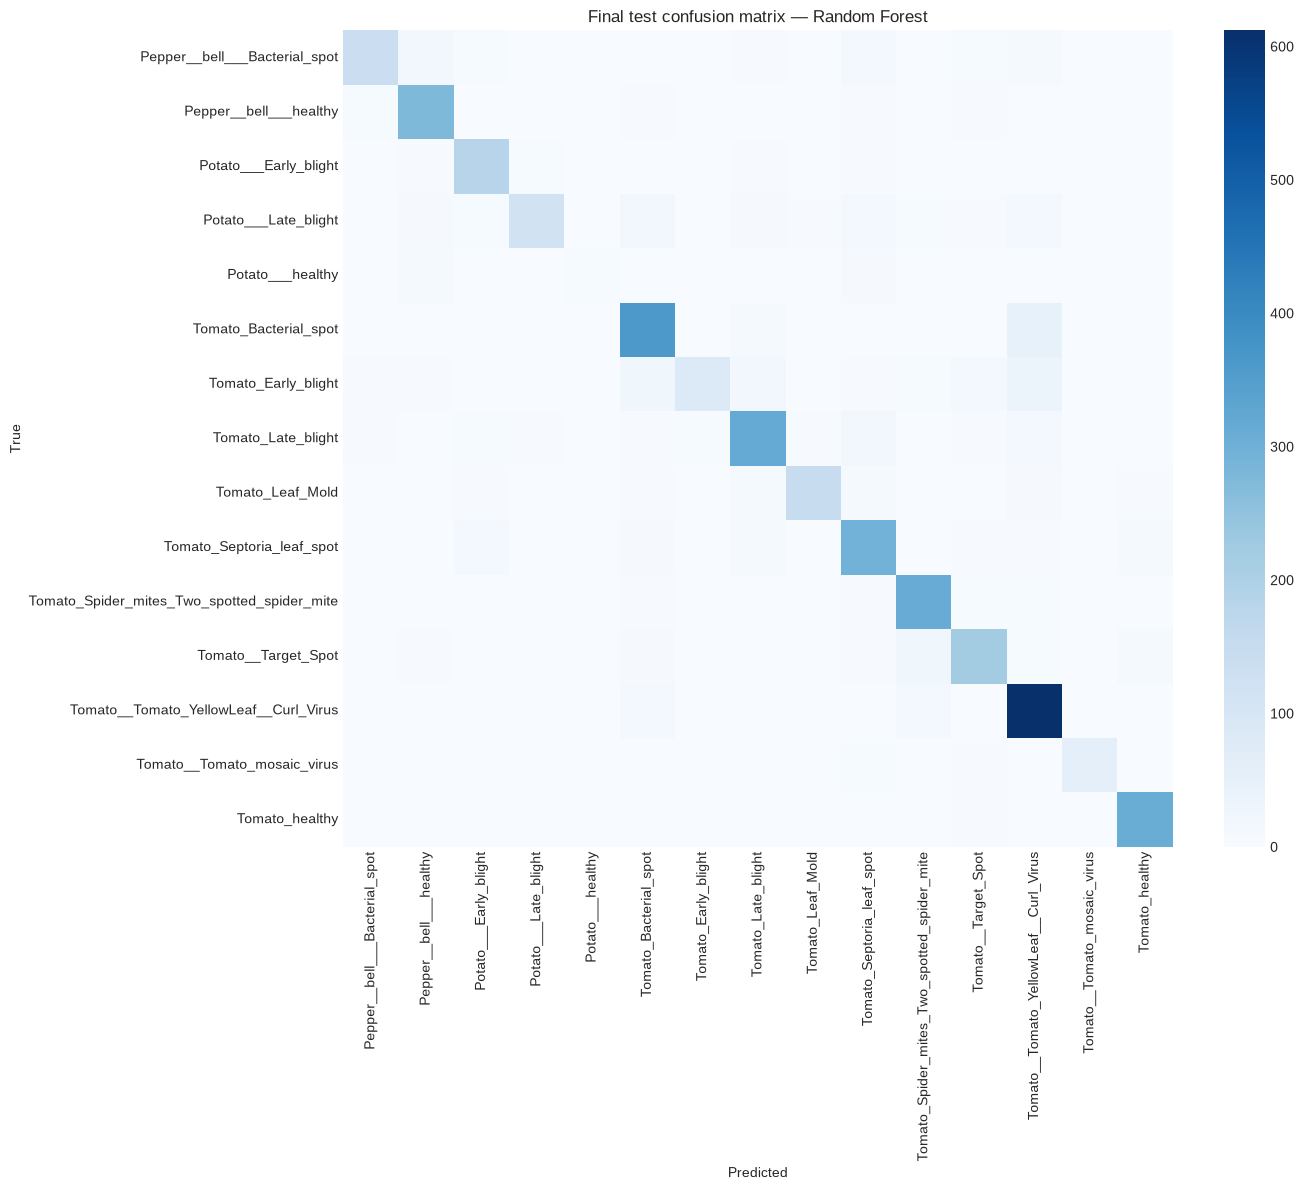

In [54]:
# Freeze choice; retrain on train+validation with unchanged hyperparameters, then test once.
X_fitval=np.concatenate([X_train_features,X_val_features]); y_fitval=np.concatenate([y_train,y_val])
final_model=joblib.clone(best_model) if hasattr(joblib,"clone") else None
from sklearn.base import clone
final_model=clone(best_model); final_model.fit(X_fitval,y_fitval)
test_predictions,test_metrics=score_model(final_model,X_test_features,y_test)
print("Final test metrics (single held-out evaluation):",test_metrics)
print(classification_report(y_test,test_predictions,zero_division=0))
cm=confusion_matrix(y_test,test_predictions,labels=final_model.classes_)
plt.figure(figsize=(14,12)); sns.heatmap(cm,cmap="Blues",xticklabels=final_model.classes_,yticklabels=final_model.classes_); plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Final test confusion matrix — {best_name}"); plt.xticks(rotation=90); plt.yticks(rotation=0); plt.tight_layout(); plt.show()


## 16. Error Analysis

In [55]:
errors=pd.DataFrame({"path":X_test_paths,"true":y_test,"predicted":test_predictions})
errors=errors[errors.true!=errors.predicted]
confusions=(errors.groupby(["true","predicted"]).size().sort_values(ascending=False).rename("count").reset_index())
display(confusions.head(20)); print(f"Misclassified test images: {len(errors):,}/{len(y_test):,}")


,true,predicted,count
0,Tomato_Bacterial_spot,Tomato__Tomato_YellowLeaf__Curl_Virus,48
1,Tomato_Early_blight,Tomato__Tomato_YellowLeaf__Curl_Virus,38
2,Tomato__Target_Spot,Tomato_Spider_mites_Two_spotted_spider_mite,24
3,Tomato_Early_blight,Tomato_Bacterial_spot,24
4,Pepper__bell___Bacterial_spot,Pepper__bell___healthy,21
5,Potato___Late_blight,Tomato_Bacterial_spot,19
6,Tomato_Early_blight,Tomato_Late_blight,18
7,Tomato_Late_blight,Tomato_Septoria_leaf_spot,18
8,Potato___Late_blight,Tomato_Septoria_leaf_spot,14
9,Pepper__bell___Bacterial_spot,Tomato_Septoria_leaf_spot,14


Misclassified test images: 682/4,122


## 17. Prediction on New Images

In [56]:
def predict_plant_leaf(image_path, model=final_model):
    image=preprocess_image(image_path)
    if image is None: raise ValueError(f"Could not read image: {image_path}")
    x=extract_all_features(image_path).reshape(1,-1)
    pred=model.predict(x)[0]
    result={"label":pred,"score_type":None,"highest_score":None}
    if hasattr(model,"predict_proba"):
        scores=model.predict_proba(x)[0]; result.update(score_type="model probability (not calibrated)",highest_score=float(scores.max()))
    elif hasattr(model,"decision_function"):
        scores=np.ravel(model.decision_function(x)); result.update(score_type="decision score (not probability)",highest_score=float(scores.max()))
    plt.figure(figsize=(5,5)); plt.imshow(image); plt.axis("off"); plt.title(f"{pred}\n{result['score_type']}: {result['highest_score']}"); plt.show()
    return result


## 18. Model Saving and Loading

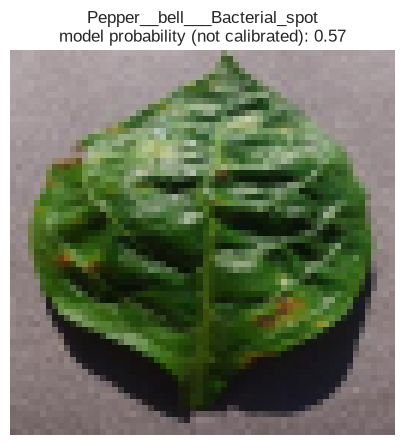

Saved and reload-verified: models/plant_leaf_final.joblib ; sample prediction: {'label': 'Pepper__bell___Bacterial_spot', 'score_type': 'model probability (not calibrated)', 'highest_score': 0.57}


In [57]:
artifact={"model":final_model,"feature_groups":{k:(v.start,v.stop) for k,v in FEATURE_GROUPS.items()},"feature_order":FEATURE_ORDER,"image_size":IMAGE_SIZE,"label_mapping":{i:label for i,label in enumerate(sorted(model_df["class"].unique()))},"hyperparameters":final_model.get_params(),"evaluation_metrics":test_metrics,"classification_report":classification_report(y_test,test_predictions,output_dict=True,zero_division=0),"baseline_validation_metrics":baseline_results.to_dict(orient="records"),"preprocessing":{"image_size":IMAGE_SIZE,"color_order":"RGB","resize_interpolation":"cv2.INTER_AREA"},"random_seed":SEED,"split_paths":{"train":list(map(str,X_train_paths)),"validation":list(map(str,X_val_paths)),"test":list(map(str,X_test_paths))},"group_assignments":{str(k):v for k,v in split_lookup.items()},"duplicate_audit":{"sha256_groups":int(sum(len(v)>1 for v in sha_groups.values())),"connected_groups":int(len(duplicate_groups)),"conflict_groups_excluded":int(len(conflicting_groups)),"phash_hamming_threshold":PHASH_MAX_HAMMING}}
artifact_path=MODEL_DIR/"plant_leaf_final.joblib"; joblib.dump(artifact,artifact_path)
metrics_path=RESULTS_DIR/"plant_leaf_final_metrics.json"; metrics_path.write_text(json.dumps(test_metrics,indent=2))
loaded=joblib.load(artifact_path); sample_result=predict_plant_leaf(X_test_paths[0],loaded["model"])
print("Saved and reload-verified:",artifact_path,"; sample prediction:",sample_result)


## 19. Limitations and Future Improvements

PlantVillage consists largely of controlled-background imagery. These grouped internal partitions do not establish field generalization, and image perceptual similarity is only a proxy for shared capture identity. Report actual measured scores from this run; prior 80/20 outputs are historical and are not comparable because they preceded duplicate auditing. External field data, reviewed duplicate clusters, and plant/session metadata are needed for stronger claims. Feature ablation, grouped CV tuning, and the full HOG extraction may be compute intensive.

## 20. Conclusion

The validation leaderboard selects the model; the test partition is used once for final reporting. No score or winner should be stated unless the corresponding computation completes.
